# 03 · Training Deep Networks Well: Generalisation, Regularisation and Strategy

Notebook 02 showed how a network *learns*: backpropagation computes gradients and an optimiser follows them downhill. That is the easy half. The hard half is that a low training loss is not the goal. The goal is a network that works on data it has **never seen**.

This notebook is about the craft between "the code runs" and "the model is good":

| Section | Question | Tools |
|---|---|---|
| 1 | How do I measure what I care about? | train / dev / test splits |
| 2-3 | Is my model too simple or too complex? | capacity sweep, bias and variance, learning curves |
| 4 | My model memorises the training set. Now what? | L2 weight decay, dropout, early stopping |
| 5 | Deep networks train slowly or diverge. Why? | batch normalisation |
| 6 | Which batch size and learning-rate schedule? | mini-batches, warm-up, cosine decay |
| 7 | How do I choose hyperparameters? | grid vs random search |
| 8 | What should I work on next? | error analysis, train/dev mismatch |

Everything runs on a CPU in a few minutes, using two datasets that ship with scikit-learn: 2-D "moons" (to see decision boundaries) and 8×8 handwritten digits.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, random, copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split

torch.manual_seed(0); np.random.seed(0); random.seed(0)
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def train(model, X, y, Xd=None, yd=None, epochs=100, lr=1e-3, wd=0.0, batch=32, schedule=None, keep_best=False):
    # a reusable training loop: Adam (+ optional decoupled weight decay), mini-batches, history of train/dev accuracy
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps_per_epoch = math.ceil(len(X) / batch)
    hist = {"train": [], "dev": [], "loss": [], "lr": []}
    best = (-1, None, 0)
    step = 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            if schedule:
                for gp in opt.param_groups:
                    gp["lr"] = schedule(step, epochs * steps_per_epoch) * lr
            b = perm[i:i + batch]
            loss = F.cross_entropy(model(X[b]), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            hist["loss"].append(loss.item()); hist["lr"].append(opt.param_groups[0]["lr"]); step += 1
        hist["train"].append(accuracy(model, X, y))
        if Xd is not None:
            hist["dev"].append(accuracy(model, Xd, yd))
            if keep_best and hist["dev"][-1] > best[0]:
                best = (hist["dev"][-1], copy.deepcopy(model.state_dict()), ep)
    if keep_best:
        model.load_state_dict(best[1]); hist["best_epoch"] = best[2]
    return hist

def mlp(sizes, dropout=0.0, batchnorm=False, act=nn.ReLU):
    layers = []
    for a, b in zip(sizes[:-2], sizes[1:-1]):
        layers.append(nn.Linear(a, b))
        if batchnorm: layers.append(nn.BatchNorm1d(b))
        layers.append(act())
        if dropout: layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(sizes[-2], sizes[-1]))
    return nn.Sequential(*layers)

## 1. Train, dev and test: measuring what you care about

A model is only useful on data it has not seen, so we hold some data back. In practice we need **three** sets:

| Set | Used for | Rule |
|---|---|---|
| **train** | fitting the weights | the optimiser sees it every step |
| **dev** (validation) | choosing *everything else*: architecture, learning rate, regularisation, when to stop | look at it as often as you like |
| **test** | one final, unbiased estimate | look at it **once**, at the very end |

Why not just train and test? Because every decision you make by looking at a score is a form of training. Try 50 configurations and keep the best test score, and that score is optimistic: you have fitted the test set by hand. The dev set absorbs that optimism so the test set stays honest.

Two more rules from practice: the dev and test sets must come from the **same distribution as the data you will see in production** (section 8 shows what happens when they do not), and with large datasets they can be a small percentage of the data: 10,000 dev examples measure accuracy to about ±0.3%, whether you have 100 thousand or 100 million training examples.

In [2]:
digits = load_digits()
X_all = torch.tensor(digits.data / 16.0, dtype=torch.float32)          # 1,797 images, flattened to 64 inputs
y_all = torch.tensor(digits.target)
idx_tmp, idx_test = train_test_split(np.arange(len(y_all)), test_size=0.2, random_state=0, stratify=y_all)
idx_train, idx_dev = train_test_split(idx_tmp, test_size=0.25, random_state=0, stratify=y_all[idx_tmp])
Xtr, ytr, Xdev, ydev, Xte, yte = X_all[idx_train], y_all[idx_train], X_all[idx_dev], y_all[idx_dev], X_all[idx_test], y_all[idx_test]
print(f"train {len(ytr)}   dev {len(ydev)}   test {len(yte)}   (60/20/20, stratified by digit)")

train 1077   dev 360   test 360   (60/20/20, stratified by digit)


## 2. Underfitting and overfitting

**Capacity** is how complicated a function a model can represent. Too little and the model cannot capture the pattern (**underfitting**, or high **bias**). Too much, with too little data, and it fits the noise in the particular training sample (**overfitting**, or high **variance**).

The two-moons dataset makes this visible. We train MLPs of increasing width on 200 noisy points, for long enough that each one fits the training data as well as it can, and look at the training and dev error.

trained 7 models in 30s


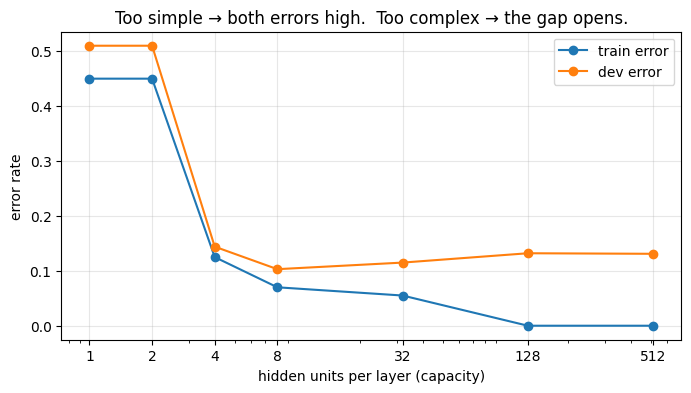

In [3]:
Xm, ym = make_moons(n_samples=1200, noise=0.35, random_state=0)
Xm, ym = torch.tensor(Xm, dtype=torch.float32), torch.tensor(ym)
Xm_tr, ym_tr, Xm_dev, ym_dev = Xm[:200], ym[:200], Xm[200:], ym[200:]

widths = [1, 2, 4, 8, 32, 128, 512]
moon_models, tr_err, dev_err = {}, [], []
t0 = time.time()
for w in widths:
    torch.manual_seed(0)
    m = mlp([2, w, w, 2])
    train(m, Xm_tr, ym_tr, epochs=600, lr=3e-3, batch=200)
    moon_models[w] = m
    tr_err.append(1 - accuracy(m, Xm_tr, ym_tr)); dev_err.append(1 - accuracy(m, Xm_dev, ym_dev))
print(f"trained {len(widths)} models in {time.time() - t0:.0f}s")

plt.figure(figsize=(8, 4))
plt.plot(widths, tr_err, "o-", label="train error"); plt.plot(widths, dev_err, "o-", label="dev error")
plt.xscale("log"); plt.xticks(widths, widths); plt.xlabel("hidden units per layer (capacity)"); plt.ylabel("error rate")
plt.title("Too simple → both errors high.  Too complex → the gap opens."); plt.legend(); plt.grid(alpha=0.3); plt.show()

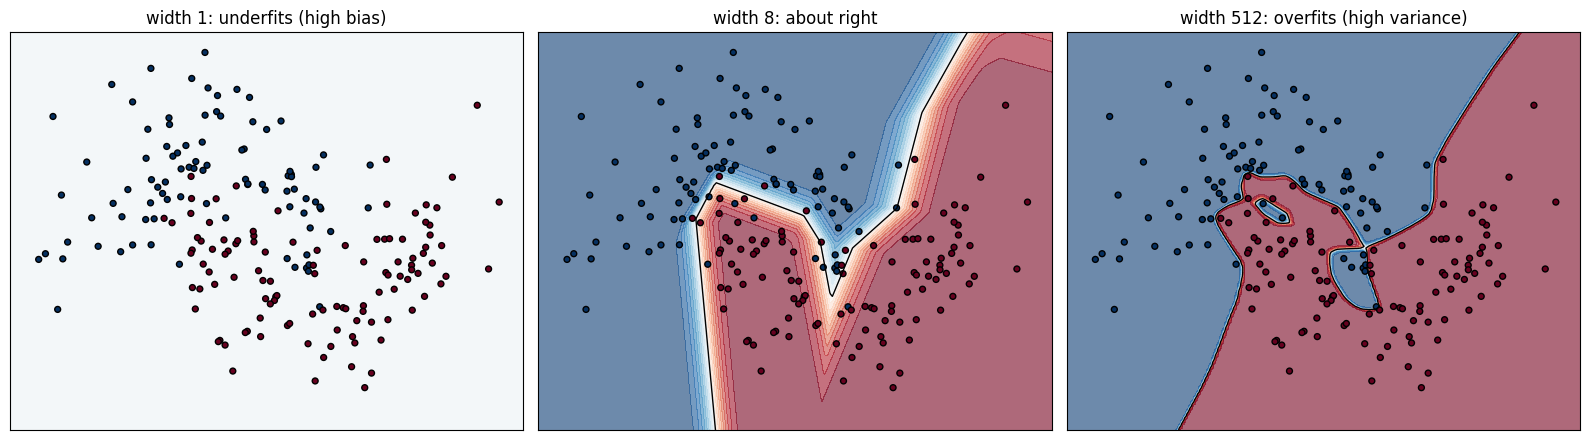

In [4]:
def plot_boundary(ax, model, X, y, title):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    model.eval()
    with torch.no_grad():
        p = model(grid).softmax(1)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, p, levels=20, cmap="RdBu_r", alpha=0.6)
    ax.contour(xx, yy, p, levels=[0.5], colors="k", linewidths=1)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", edgecolors="k", s=18)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, w, label in zip(axes, [1, 8, 512], ["underfits (high bias)", "about right", "overfits (high variance)"]):
    plot_boundary(ax, moon_models[w], Xm_tr, ym_tr, f"width {w}: {label}")
plt.tight_layout(); plt.show()

The widest network carves out little islands around individual noisy points: it has memorised the training sample. The narrowest one is so constrained that it cannot represent the curve at all: here its single ReLU unit ended up inactive ("dead", notebook 01), so it predicts the same class almost everywhere and sits at about 50% error.

## 3. Diagnosing bias and variance

You rarely get to plot the decision boundary, but you can always compare four numbers:

| | Example A | Example B | Example C | Example D |
|---|---|---|---|---|
| reference error (best achievable, e.g. human) | 1% | 1% | 1% | 1% |
| train error | 1.5% | 12% | 12% | 1.5% |
| dev error | 11% | 13% | 25% | 2% |
| diagnosis | **high variance** | **high bias** | **both** | good |

* **Avoidable bias** = train error − reference error. Fix with a bigger model, longer training, a better architecture.
* **Variance** = dev error − train error. Fix with more data, regularisation (section 4), data augmentation, a smaller model.

**Learning curves** add a second view: train the same model on growing slices of the training set. If the two curves have converged at a high error, more data will not help (bias). If there is a large gap that is still closing, more data will.

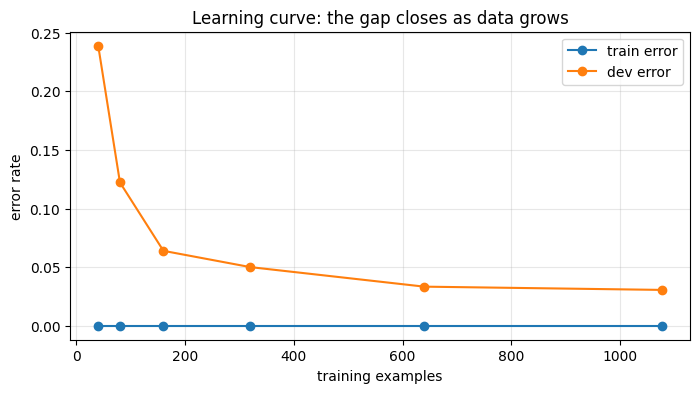

   40 examples   train error  0.0%   dev error 23.9%
   80 examples   train error  0.0%   dev error 12.2%
  160 examples   train error  0.0%   dev error  6.4%
  320 examples   train error  0.0%   dev error  5.0%
  640 examples   train error  0.0%   dev error  3.3%
 1077 examples   train error  0.0%   dev error  3.1%


In [5]:
sizes = [40, 80, 160, 320, 640, len(ytr)]
lc_tr, lc_dev = [], []
for n in sizes:
    torch.manual_seed(0)
    m = mlp([64, 256, 256, 10])
    train(m, Xtr[:n], ytr[:n], epochs=150, lr=1e-3, batch=32)
    lc_tr.append(1 - accuracy(m, Xtr[:n], ytr[:n])); lc_dev.append(1 - accuracy(m, Xdev, ydev))
plt.figure(figsize=(8, 4))
plt.plot(sizes, lc_tr, "o-", label="train error"); plt.plot(sizes, lc_dev, "o-", label="dev error")
plt.xlabel("training examples"); plt.ylabel("error rate"); plt.title("Learning curve: the gap closes as data grows")
plt.legend(); plt.grid(alpha=0.3); plt.show()
for n, a, b in zip(sizes, lc_tr, lc_dev):
    print(f"{n:5d} examples   train error {a:5.1%}   dev error {b:5.1%}")

Training error is zero at every size: this network has plenty of capacity. Dev error keeps falling as the data grows, so this model is limited by **variance**, and more data or regularisation is the right lever.

## 4. Regularisation: the toolbox against overfitting

To make overfitting obvious we deliberately starve a large network: 64 → 512 → 512 → 10 (about 300,000 parameters) trained on only **200** digits. Then we try the standard remedies, one at a time.

**L2 regularisation / weight decay.** Add $\frac{\lambda}{2}\sum w^2$ to the loss, or equivalently shrink every weight a little each step: $w \leftarrow w - \eta(\nabla_w \mathcal{L} + \lambda w)$. Large weights let a network build sharp, wiggly functions; keeping them small keeps the function smooth. With Adam, the "decoupled" version (**AdamW**, used here) works better than adding the penalty to the loss.

**Dropout** (Srivastava et al., 2014). During training, zero each hidden unit with probability $p$ and scale the survivors by $1/(1-p)$ so the expected activation is unchanged. No unit can rely on any particular other unit being present, so the network learns redundant, more robust features. It behaves like training a huge ensemble of thinned networks that share weights. At test time dropout is switched off.

**Early stopping.** Watch the dev accuracy during training and keep the weights from the best epoch. Free, simple, and almost always worth doing.

In [6]:
class MyDropout(nn.Module):
    # "inverted" dropout, written by hand; behaves exactly like nn.Dropout
    def __init__(self, p):
        super().__init__(); self.p = p
    def forward(self, x):
        if not self.training or self.p == 0:
            return x                                       # at test time: do nothing
        mask = (torch.rand_like(x) > self.p).float()
        return x * mask / (1 - self.p)                     # rescale so E[output] = x

d = MyDropout(0.5); d.train()
x = torch.ones(1, 10)
print("training mode:", d(x).numpy().round(1), "  mean over many draws:", round(d(torch.ones(10000, 10)).mean().item(), 3))
d.eval(); print("eval mode    :", d(x).numpy().round(1))

training mode: [[0. 2. 0. 0. 0. 2. 0. 0. 0. 2.]]   mean over many draws: 1.002
eval mode    : [[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]


trained 5 models in 121s

                          train acc   dev acc
no regularisation            100.0%     94.4%
L2 weight decay              100.0%     95.0%
dropout 0.5                  100.0%     95.6%
early stopping               100.0%     94.7%   (best epoch 185)
dropout + L2 + early         100.0%     95.8%   (best epoch 196)


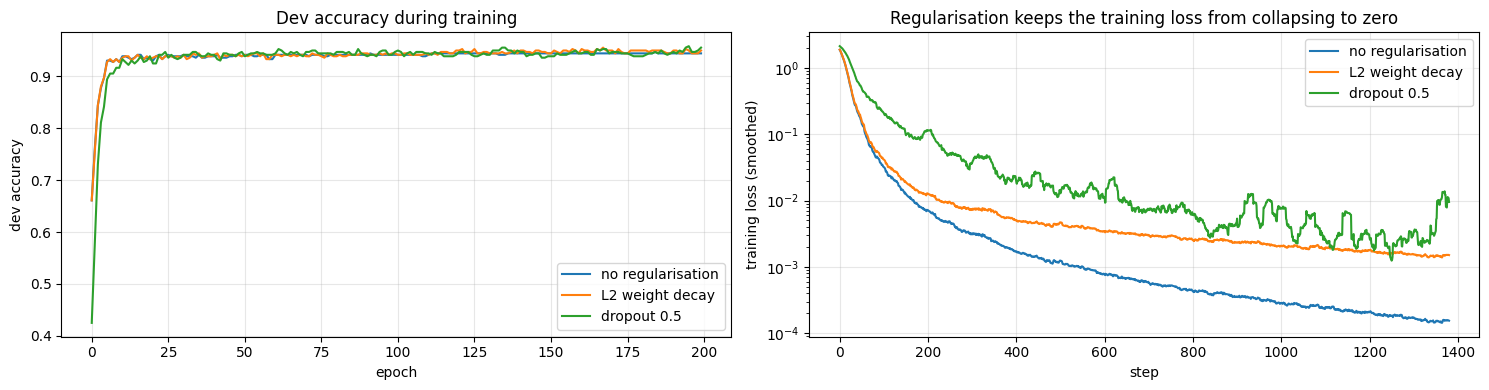

In [7]:
Xs, ys = Xtr[:200], ytr[:200]                                         # the starved training set
configs = {
    "no regularisation":       dict(model=lambda: mlp([64, 512, 512, 10]),              wd=0.0, keep_best=False),
    "L2 weight decay":         dict(model=lambda: mlp([64, 512, 512, 10]),              wd=0.5, keep_best=False),
    "dropout 0.5":             dict(model=lambda: mlp([64, 512, 512, 10], dropout=0.5), wd=0.0, keep_best=False),
    "early stopping":          dict(model=lambda: mlp([64, 512, 512, 10]),              wd=0.0, keep_best=True),
    "dropout + L2 + early":    dict(model=lambda: mlp([64, 512, 512, 10], dropout=0.5), wd=0.5, keep_best=True),
}
reg_hist, reg_models = {}, {}
t0 = time.time()
for name, cfg in configs.items():
    torch.manual_seed(0)
    m = cfg["model"]()
    reg_hist[name] = train(m, Xs, ys, Xdev, ydev, epochs=200, lr=1e-3, wd=cfg["wd"], batch=32, keep_best=cfg["keep_best"])
    reg_models[name] = m
print(f"trained {len(configs)} models in {time.time() - t0:.0f}s\n")
print(f"{'':24s} {'train acc':>10s} {'dev acc':>9s}")
for name, m in reg_models.items():
    extra = f"   (best epoch {reg_hist[name]['best_epoch'] + 1})" if "best_epoch" in reg_hist[name] else ""
    print(f"{name:24s} {accuracy(m, Xs, ys):10.1%} {accuracy(m, Xdev, ydev):9.1%}{extra}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for name in ["no regularisation", "L2 weight decay", "dropout 0.5"]:
    axes[0].plot(reg_hist[name]["dev"], label=name)
    axes[1].plot(np.convolve(reg_hist[name]["loss"], np.ones(20) / 20, mode="valid"), label=name)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("dev accuracy"); axes[0].set_title("Dev accuracy during training")
axes[1].set_xlabel("step"); axes[1].set_ylabel("training loss (smoothed)"); axes[1].set_yscale("log"); axes[1].set_title("Regularisation keeps the training loss from collapsing to zero")
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Each remedy gains about a point of dev accuracy, and combined they gain more. The gains are modest here because 8×8 digits are an easy problem even for an overfitted network; on harder data with more noise the same tools are often worth several points. The right-hand plot shows the mechanism: without regularisation the training loss heads towards zero (memorisation); with it the network is kept from becoming over-confident on the training points. Note that training accuracy stays at 100% in every row: regularisation does not stop the network fitting the training set, it changes *how* it fits it.

Other regularisers you will meet: **data augmentation** (notebook 04, often the strongest of all for images), **label smoothing**, smaller models, and simply more data.

## 5. Batch normalisation

Each layer's input distribution changes as the layers before it learn, and in a deep network small changes compound. Badly scaled activations push units into saturation (notebook 01) and force a small learning rate.

**Batch normalisation** (Ioffe & Szegedy, 2015) normalises every unit over the current mini-batch, then lets the network rescale it with two learned parameters per unit:

$$ \hat z = \frac{z - \mu_{\text{batch}}}{\sqrt{\sigma^2_{\text{batch}} + \epsilon}}, \qquad \text{BN}(z) = \gamma \hat z + \beta $$

At test time there may be a single example and no batch, so BN uses **running averages** of $\mu$ and $\sigma^2$ collected during training. Forgetting to switch between `model.train()` and `model.eval()` is a classic bug for exactly this reason.

In [8]:
class MyBatchNorm(nn.Module):
    def __init__(self, n, momentum=0.1, eps=1e-5):
        super().__init__()
        self.gamma, self.beta = nn.Parameter(torch.ones(n)), nn.Parameter(torch.zeros(n))
        self.register_buffer("run_mean", torch.zeros(n)); self.register_buffer("run_var", torch.ones(n))
        self.momentum, self.eps = momentum, eps
    def forward(self, z):
        if self.training:
            mu, var = z.mean(0), z.var(0, unbiased=False)
            with torch.no_grad():                         # remember the statistics for test time
                self.run_mean.lerp_(mu, self.momentum); self.run_var.lerp_(var, self.momentum)
        else:
            mu, var = self.run_mean, self.run_var
        return self.gamma * (z - mu) / torch.sqrt(var + self.eps) + self.beta

z = torch.randn(256, 4) * torch.tensor([1.0, 10.0, 0.1, 3.0]) + torch.tensor([5.0, -20.0, 0.0, 1.0])
bn, ref = MyBatchNorm(4), nn.BatchNorm1d(4)
print("input mean/std per unit :", z.mean(0).numpy().round(2), z.std(0).numpy().round(2))
print("after BN mean/std       :", bn(z).mean(0).detach().numpy().round(2), bn(z).std(0).detach().numpy().round(2))
print("matches nn.BatchNorm1d  :", torch.allclose(bn(z), ref(z), atol=1e-5))

input mean/std per unit : [  4.94 -18.97   0.     0.98] [ 0.98 10.08  0.1   2.92]
after BN mean/std       : [ 0.  0. -0.  0.] [1. 1. 1. 1.]
matches nn.BatchNorm1d  : True


The experiment: a **10-layer** MLP with sigmoid activations on the digits, trained with the same learning rate with and without BN. Sigmoids saturate easily, which makes deep sigmoid networks hard to train, a worst case that BN was designed for.

10 layers, no BN     dev accuracy after 30 epochs: 10.3%  (7s)


10 layers, with BN   dev accuracy after 30 epochs: 95.6%  (22s)


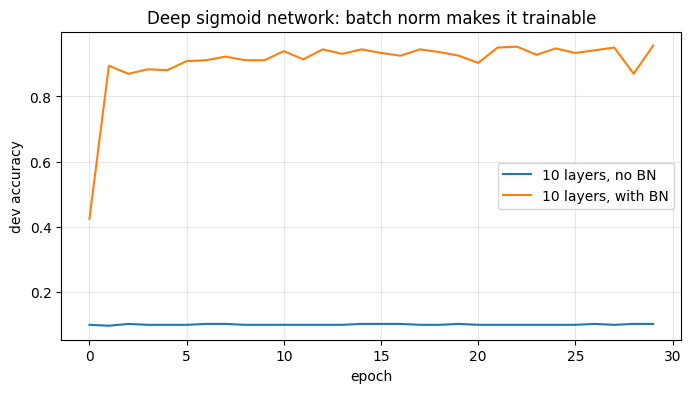

In [9]:
bn_hist = {}
for name, use_bn in [("10 layers, no BN", False), ("10 layers, with BN", True)]:
    torch.manual_seed(0)
    m = mlp([64] + [128] * 10 + [10], batchnorm=use_bn, act=nn.Sigmoid)
    t0 = time.time()
    bn_hist[name] = train(m, Xtr, ytr, Xdev, ydev, epochs=30, lr=1e-2, batch=64)
    print(f"{name:20s} dev accuracy after 30 epochs: {bn_hist[name]['dev'][-1]:.1%}  ({time.time() - t0:.0f}s)")
plt.figure(figsize=(8, 4))
for name, h in bn_hist.items():
    plt.plot(h["dev"], label=name)
plt.xlabel("epoch"); plt.ylabel("dev accuracy"); plt.title("Deep sigmoid network: batch norm makes it trainable")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Batch norm also has a mild regularising effect (each example's normalisation depends on the random batch it lands in). Transformers use the closely related **LayerNorm** (notebook 07), which normalises over the features of a single example instead of over the batch, so it works the same way in training and at inference time and does not depend on the batch size.

## 6. Mini-batches and learning-rate schedules

**Batch size.** Full-batch gradient descent computes the exact gradient but takes one step per epoch. Pure stochastic gradient descent (batch of 1) takes many cheap, noisy steps. Mini-batches (typically 32 to 1024) sit in between: enough examples to use vectorised hardware efficiently, enough steps per epoch to make fast progress, and a little gradient noise that often helps generalisation.

In [10]:
print(f"{'batch size':>10s} {'steps/epoch':>12s} {'dev acc after 20 epochs':>24s} {'time':>6s}")
batch_hist = {}
for b in [8, 64, len(ytr)]:
    torch.manual_seed(0)
    m = mlp([64, 128, 10])
    t0 = time.time()
    batch_hist[b] = train(m, Xtr, ytr, Xdev, ydev, epochs=20, lr=1e-3, batch=b)
    print(f"{b:10d} {math.ceil(len(ytr) / b):12d} {batch_hist[b]['dev'][-1]:24.1%} {time.time() - t0:5.1f}s")

batch size  steps/epoch  dev acc after 20 epochs   time


         8          135                    97.2%  15.6s


        64           17                    95.3%   0.7s
      1077            1                    80.8%   0.2s


With the same number of epochs (the same amount of data seen), full-batch training is far behind because it made only 20 updates. Small batches made the most progress, but each epoch costs more wall-clock time on parallel hardware. Large-batch training usually needs a larger learning rate to compensate.

**Learning-rate schedules.** A large learning rate makes fast progress early but bounces around the minimum later; a small one is precise but slow. Schedules get both:

* **step decay:** divide the learning rate by 10 at fixed points;
* **warm-up + cosine decay:** ramp up linearly for the first few percent of steps (protecting the randomly initialised network, and Adam's still-unreliable statistics, from huge early updates), then follow half a cosine down to zero. This is the default for transformers and GPT-style models (notebook 08).

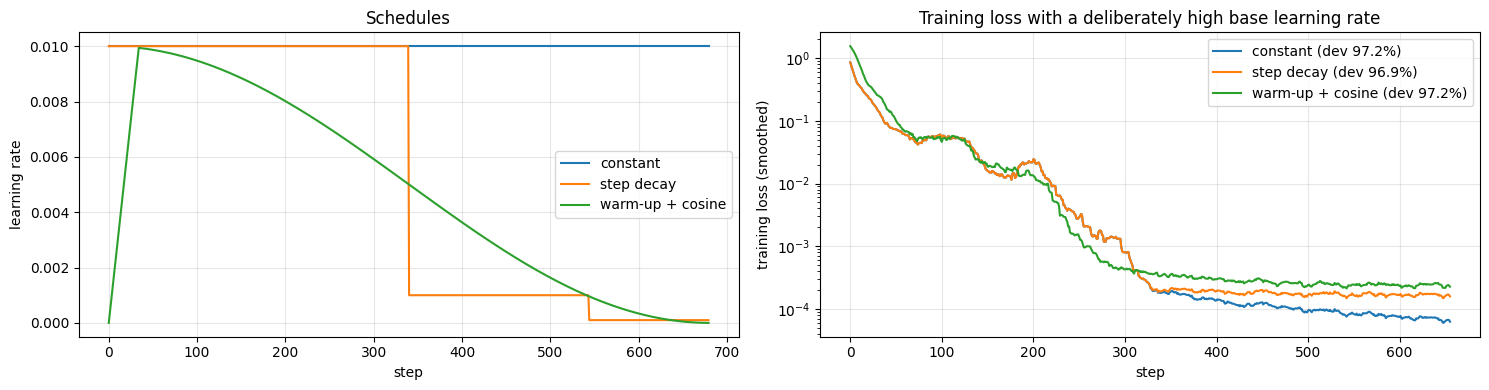

In [11]:
schedules = {
    "constant":         None,
    "step decay":       lambda s, total: 1.0 if s < 0.5 * total else (0.1 if s < 0.8 * total else 0.01),
    "warm-up + cosine": lambda s, total: min(1.0, s / (0.05 * total)) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))),
}
sched_hist = {}
for name, sch in schedules.items():
    torch.manual_seed(0)
    m = mlp([64, 256, 256, 10])
    sched_hist[name] = train(m, Xtr, ytr, Xdev, ydev, epochs=40, lr=1e-2, batch=64, schedule=sch)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for name, h in sched_hist.items():
    axes[0].plot(h["lr"], label=name)
    axes[1].plot(np.convolve(h["loss"], np.ones(25) / 25, mode="valid"), label=f"{name} (dev {h['dev'][-1]:.1%})")
axes[0].set_xlabel("step"); axes[0].set_ylabel("learning rate"); axes[0].set_title("Schedules")
axes[1].set_xlabel("step"); axes[1].set_ylabel("training loss (smoothed)"); axes[1].set_yscale("log"); axes[1].set_title("Training loss with a deliberately high base learning rate")
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

With a base learning rate that is too high to settle, the constant schedule stays noisy; the decaying schedules use the same high rate early and then settle into a much lower loss.

## 7. Choosing hyperparameters: grid search vs random search

A network has many knobs (learning rate, weight decay, width, dropout, batch size…) and they are **not equally important**. The learning rate almost always matters most.

**Grid search** tries every combination of a few values per knob. **Random search** samples each knob independently. Bergstra & Bengio (2012) pointed out why random search usually wins for the same budget: with 9 trials on a 3×3 grid you only ever try **3** distinct learning rates; with 9 random trials you try 9. When one knob dominates, random search explores it three times more densely.

Two practical rules: sample scale-like parameters (learning rate, weight decay) **on a log scale**, and select on the **dev** set, never on the test set.

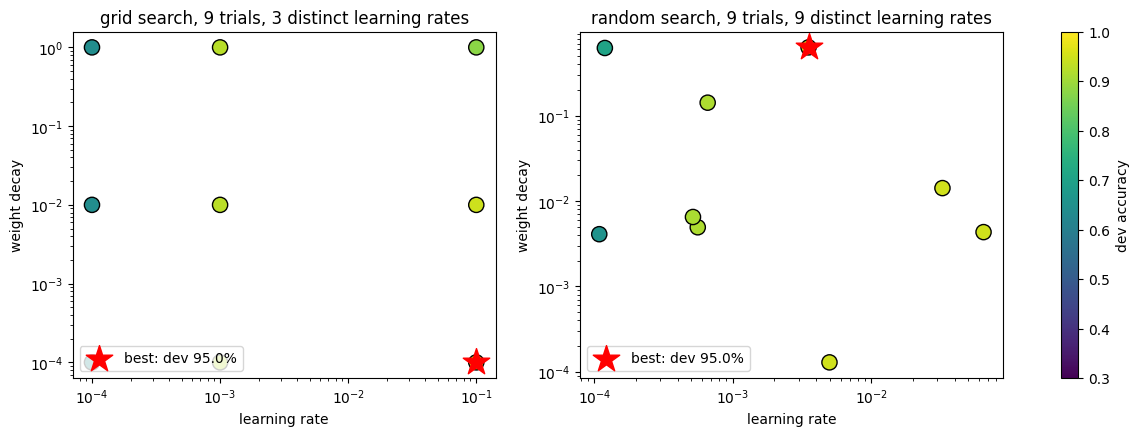

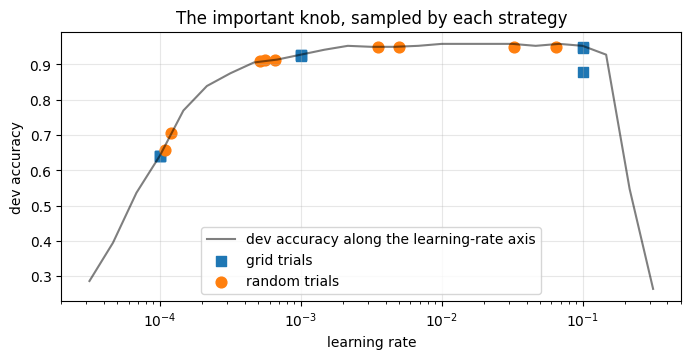

grid   best: lr=1.00e-01 wd=1.00e-04  dev 95.0%  →  test 93.3% (reported once)
random best: lr=3.53e-03 wd=6.34e-01  dev 95.0%  →  test 94.2% (reported once)


In [12]:
def trial(lr, wd, seed=0):
    torch.manual_seed(seed)
    m = mlp([64, 128, 10])
    train(m, Xtr[:400], ytr[:400], epochs=15, lr=lr, wd=wd, batch=32)
    return accuracy(m, Xdev, ydev), m

grid = [(lr, wd) for lr in [1e-4, 1e-3, 1e-1] for wd in [1e-4, 1e-2, 1]]
rng = np.random.default_rng(1)
rand = [(10 ** rng.uniform(-4.5, -0.5), 10 ** rng.uniform(-4, 0)) for _ in range(9)]
search = {"grid": [(lr, wd, *trial(lr, wd)) for lr, wd in grid],
          "random": [(lr, wd, *trial(lr, wd)) for lr, wd in rand]}

# the dense "truth" along the important axis, to see what each search could have found
lrs = np.logspace(-4.5, -0.5, 25)
dense = [trial(lr, 1e-3)[0] for lr in lrs]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (name, res) in zip(axes, search.items()):
    sc = ax.scatter([r[0] for r in res], [r[1] for r in res], c=[r[2] for r in res], cmap="viridis", vmin=0.3, vmax=1, s=120, edgecolors="k")
    best = max(res, key=lambda r: r[2])
    ax.scatter([best[0]], [best[1]], marker="*", s=400, color="red", label=f"best: dev {best[2]:.1%}")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("learning rate"); ax.set_ylabel("weight decay")
    ax.set_title(f"{name} search, 9 trials, {len(set(round(r[0], 12) for r in res))} distinct learning rates"); ax.legend(loc="lower left")
plt.colorbar(sc, ax=axes, label="dev accuracy"); plt.show()

plt.figure(figsize=(8, 3.5))
plt.semilogx(lrs, dense, "k-", alpha=0.5, label="dev accuracy along the learning-rate axis")
for name, marker in [("grid", "s"), ("random", "o")]:
    plt.scatter([r[0] for r in search[name]], [r[2] for r in search[name]], marker=marker, s=60, label=f"{name} trials")
plt.xlabel("learning rate"); plt.ylabel("dev accuracy"); plt.legend(); plt.grid(alpha=0.3); plt.title("The important knob, sampled by each strategy"); plt.show()

for name, res in search.items():
    lr, wd, dev, m = max(res, key=lambda r: r[2])
    print(f"{name:6s} best: lr={lr:.2e} wd={wd:.2e}  dev {dev:.1%}  →  test {accuracy(m, Xte, yte):.1%} (reported once)")

With 9 trials both strategies happened to find equally good settings here, but look at the second plot: the grid tried only three learning rates, one of them far too high, while random search covered the useful range. With more knobs, or a narrower sweet spot, that coverage is what makes random search win on average (exercise 4 measures it). In real projects the budget is larger and the search smarter (coarse-to-fine random search, Bayesian optimisation, or simply copying hyperparameters from a published model of similar size), but the principles stay: log scales, random over grid, select on dev, report test once.

## 8. Strategy: what should I work on next?

A lot of wasted months in machine learning come from improving the wrong thing. Two habits help.

### Error analysis

Look at the dev-set mistakes and **count** them by category before deciding what to fix. If 40% of errors are one confusion and 2% are another, the first is worth a week of work and the second is not (its *ceiling* is a 2% improvement, however perfectly you solve it). It takes an hour and regularly changes the plan.

dev accuracy 98.1%: 7 mistakes out of 360

most common confusions (true → predicted), as a share of all mistakes:
  8 → 1:  1  (14%)
  5 → 1:  1  (14%)
  3 → 8:  1  (14%)
  7 → 9:  1  (14%)
  4 → 8:  1  (14%)
  0 → 4:  1  (14%)


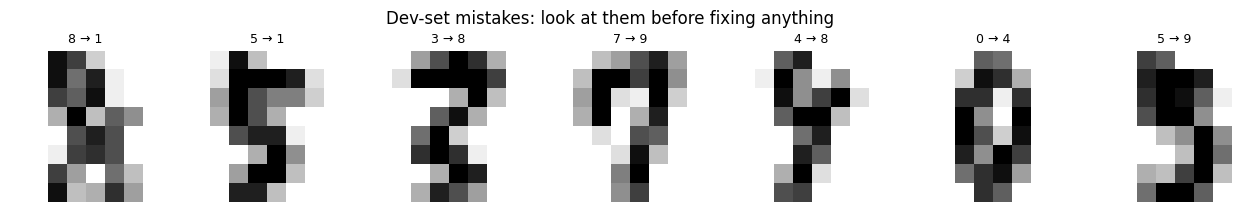

In [13]:
torch.manual_seed(0)
model = mlp([64, 256, 256, 10], dropout=0.3)
train(model, Xtr, ytr, Xdev, ydev, epochs=60, lr=1e-3, wd=1e-2, batch=32, keep_best=True)
model.eval()
with torch.no_grad():
    pred = model(Xdev).argmax(1)
wrong = (pred != ydev).nonzero().ravel()
print(f"dev accuracy {accuracy(model, Xdev, ydev):.1%}: {len(wrong)} mistakes out of {len(ydev)}\n")

from collections import Counter
pairs = Counter((ydev[i].item(), pred[i].item()) for i in wrong)
print("most common confusions (true → predicted), as a share of all mistakes:")
for (t, p), n in pairs.most_common(6):
    print(f"  {t} → {p}: {n:2d}  ({n / len(wrong):.0%})")

fig, axes = plt.subplots(1, min(10, len(wrong)), figsize=(16, 2), squeeze=False)
for ax, i in zip(axes[0], wrong[:10]):
    ax.imshow(Xdev[i].reshape(8, 8), cmap="gray_r"); ax.axis("off"); ax.set_title(f"{ydev[i].item()} → {pred[i].item()}", fontsize=9)
plt.suptitle("Dev-set mistakes: look at them before fixing anything", y=1.08); plt.show()

With only a handful of dev mistakes, no category dominates, and that is itself a finding: this model is near the point where the next gain needs **more dev data** to even measure. Error analysis pays off most when there are dozens or hundreds of errors to sort.

### When training data and real data differ

Often the data you can collect in bulk is not quite the data you will meet in production: web photos vs phone-camera photos, studio audio vs a noisy car, or here, **clean scanned digits for training** vs **smudged, noisy digits from a cheap scanner** in production.

Rule one: the dev and test sets must look like **production**, because that is the target. But then a gap between train and dev error mixes two causes: variance *and* the distribution shift. To separate them, hold out a **train-dev** set: same distribution as training, not trained on.

| Gap | Meaning |
|---|---|
| train error − reference error | avoidable bias |
| train-dev error − train error | variance |
| dev error − train-dev error | **data mismatch** |

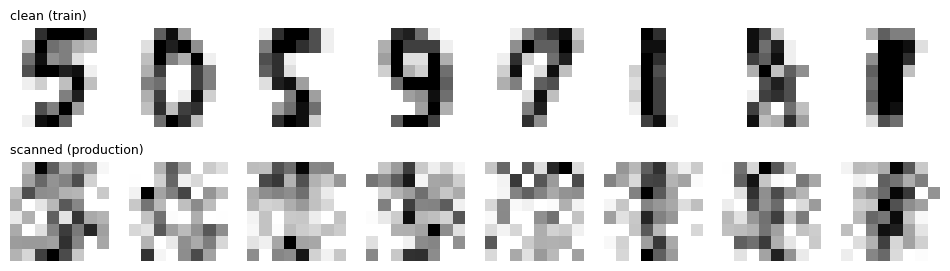

trained on clean digits only:
  train  0.0%   train-dev  2.5%   dev (scanned) 65.0%
  → variance +2.5%   data mismatch +62.5%


In [14]:
def scanner(x, seed):
    # simulate a cheap scanner: blur, faded ink and speckle noise
    g = torch.Generator().manual_seed(seed)
    img = x.reshape(-1, 1, 8, 8)
    img = F.avg_pool2d(F.pad(img, (1, 1, 1, 1), mode="replicate"), 3, stride=1)       # 3x3 blur
    img = img * (0.5 + 0.5 * torch.rand(len(img), 1, 1, 1, generator=g))               # faded ink
    img = img + 0.25 * torch.randn(img.shape, generator=g)                             # speckle
    return img.clamp(0, 1).reshape(len(x), 64)

# training data: clean (plus a held-out train-dev slice of the same clean distribution)
Xc_tr, yc_tr, Xc_trdev, yc_trdev = Xtr[:800], ytr[:800], Xtr[800:], ytr[800:]
# dev and test: production data, i.e. scanned
Xs_dev, Xs_te = scanner(Xdev, 1), scanner(Xte, 2)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for k in range(8):
    axes[0, k].imshow(Xdev[k].reshape(8, 8), cmap="gray_r"); axes[1, k].imshow(Xs_dev[k].reshape(8, 8), cmap="gray_r")
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].set_title("clean (train)", loc="left", fontsize=9); axes[1, 0].set_title("scanned (production)", loc="left", fontsize=9)
plt.show()

def report(model, label):
    e_tr = 1 - accuracy(model, Xc_tr, yc_tr); e_trdev = 1 - accuracy(model, Xc_trdev, yc_trdev); e_dev = 1 - accuracy(model, Xs_dev, ydev)
    print(f"{label}\n  train {e_tr:5.1%}   train-dev {e_trdev:5.1%}   dev (scanned) {e_dev:5.1%}")
    print(f"  → variance {e_trdev - e_tr:+.1%}   data mismatch {e_dev - e_trdev:+.1%}")

torch.manual_seed(0)
clean_model = mlp([64, 256, 256, 10], dropout=0.3)
train(clean_model, Xc_tr, yc_tr, epochs=60, lr=1e-3, wd=1e-2, batch=32)
report(clean_model, "trained on clean digits only:")

The diagnosis is unambiguous: variance is small, the data mismatch is the problem. More clean data or more regularisation would not help. What helps is making the training data **look more like production**. Here we know roughly what the scanner does, so we can **synthesise** production-like training data from the clean images (the same idea as data augmentation). In real projects you might instead collect a small amount of real production data and add it to the training set.

In [15]:
X_aug = torch.cat([Xc_tr, scanner(Xc_tr, 10), scanner(Xc_tr, 11)])     # clean + two synthetic "scanned" copies
y_aug = torch.cat([yc_tr, yc_tr, yc_tr])
torch.manual_seed(0)
aug_model = mlp([64, 256, 256, 10], dropout=0.3)
train(aug_model, X_aug, y_aug, epochs=30, lr=1e-3, wd=1e-2, batch=32)
report(aug_model, "trained on clean + synthetic scanned digits:")
print(f"\nfinal check on the untouched scanned TEST set: clean-only {accuracy(clean_model, Xs_te, yte):.1%}  vs  with synthesis {accuracy(aug_model, Xs_te, yte):.1%}")

trained on clean + synthetic scanned digits:
  train  0.6%   train-dev  2.9%   dev (scanned) 41.1%
  → variance +2.3%   data mismatch +38.2%

final check on the untouched scanned TEST set: clean-only 36.4%  vs  with synthesis 51.1%


A caveat from practice: synthetic data only fixes the mismatch you *modelled*. If the real scanner also rotates pages and our simulation does not, the model will still fail on rotation, and it can even overfit to the quirks of the simulation. Always confirm with real production data in the dev and test sets.

## Key takeaways

* The goal is low error on **unseen** data. Use train / dev / test, choose everything on dev, and report test once.
* Compare train error with a reference and with dev error to decide between **bias** fixes (bigger model, longer training) and **variance** fixes (data, regularisation).
* **Weight decay, dropout and early stopping** each fight overfitting and they combine well.
* **Batch normalisation** keeps activations well scaled, making deep networks trainable at higher learning rates.
* **Mini-batches** plus a **warm-up + decay schedule** are the default recipe for training.
* Search hyperparameters **randomly on log scales**; the learning rate matters most.
* Do **error analysis** before deciding what to fix, and use a **train-dev** set to separate variance from **data mismatch**.

## Exercises

1. In section 2, repeat the capacity sweep with 2,000 training points instead of 200. Where does overfitting start now?
2. In section 4, sweep the weight decay over `[0.01, 0.1, 0.5, 2, 5]`. Plot dev accuracy against weight decay: where is the sweet spot, and what happens beyond it?
3. Replace `nn.BatchNorm1d` with `nn.LayerNorm` in the 10-layer sigmoid network. Does it help as much?
4. Give random search and grid search 25 trials each. Repeat with 5 different seeds for the random sampler: how often does random search win?
5. Make the scanner also shift each image by one pixel in a random direction, but keep the synthesised training data unchanged. What happens to the data-mismatch number?